In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from sklearn.cross_decomposition import PLSCanonical


from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/../../../utils/train_utils.py'>

In [3]:
dims = 2

# read_ids = list(range(0, 12+1))
# read_ids = [0,   # paper
# 			2,
# 			3,
# 			4,
# 			5,
# 			6,
# 			8,
# 			9]   # good
read_ids = [0]
plot_id = 0

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]
markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]
markers_grad_zs = [
	pd.DataFrame(
		data=(marker_grad.values - marker_grad.values.mean(axis=0)) / np.where((marker_grad_std := np.std(marker_grad.values, axis=0)) == 0.0, 1.0, marker_grad_std),
		columns=marker_grad.columns)
	for marker_grad in markers_grad
]

In [6]:
selection_bhl = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

plot_idx = file_ids.index(plot_id)

# states = [s[selection_bhl] for s in states]

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces,
												 n_pc=dims)

In [8]:
traces_residuals = [pd.DataFrame(data=t.values - t_man.values, columns=t.columns) for t, t_man in zip(traces, recos_manifold)]

# traces_residuals = list()
# for file_id in file_ids:
# 	traces_residuals.append(pd.read_csv(f'../out/data/residuals/{file_id}_{filenames[file_ids.index(file_id)]}.csv', index_col=0))

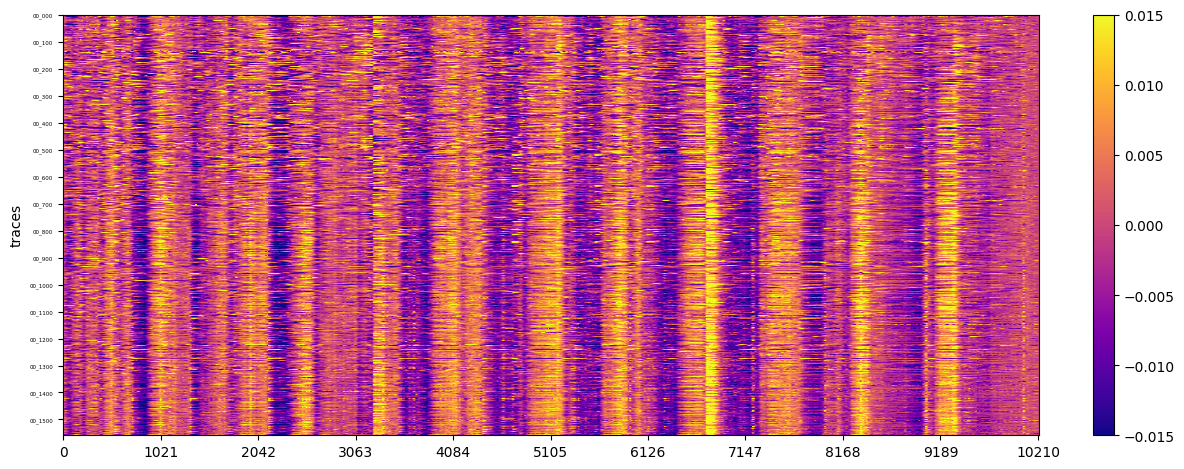

In [9]:
plot_utils.plot_heatmap_stack(traces[plot_idx], None,
							  'traces', None,
							  zlimits_activity=(-0.015, 0.015), cmap='plasma')

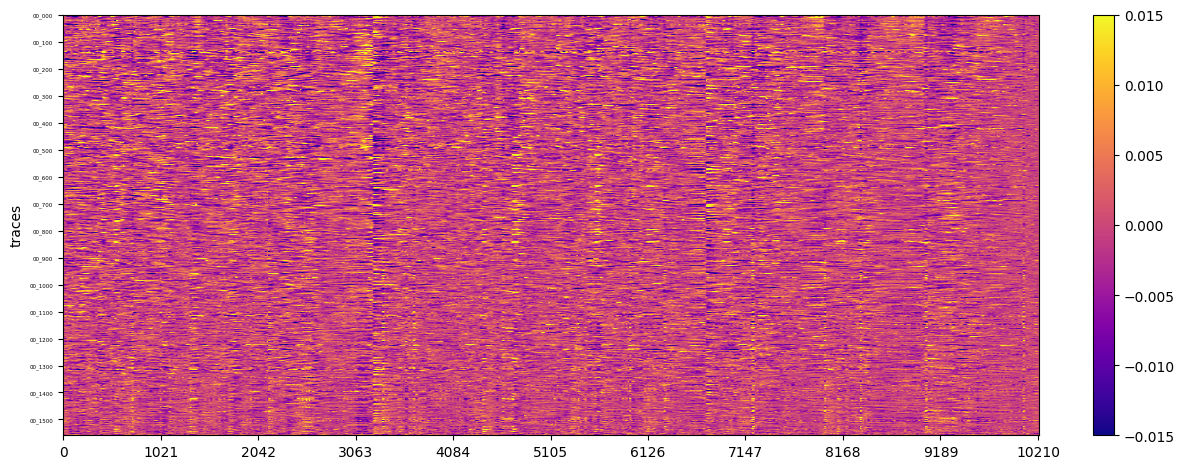

In [10]:
plot_utils.plot_heatmap_stack(traces_residuals[plot_idx], None,
							  'traces', None,
							  zlimits_activity=(-0.015, 0.015), cmap='plasma')

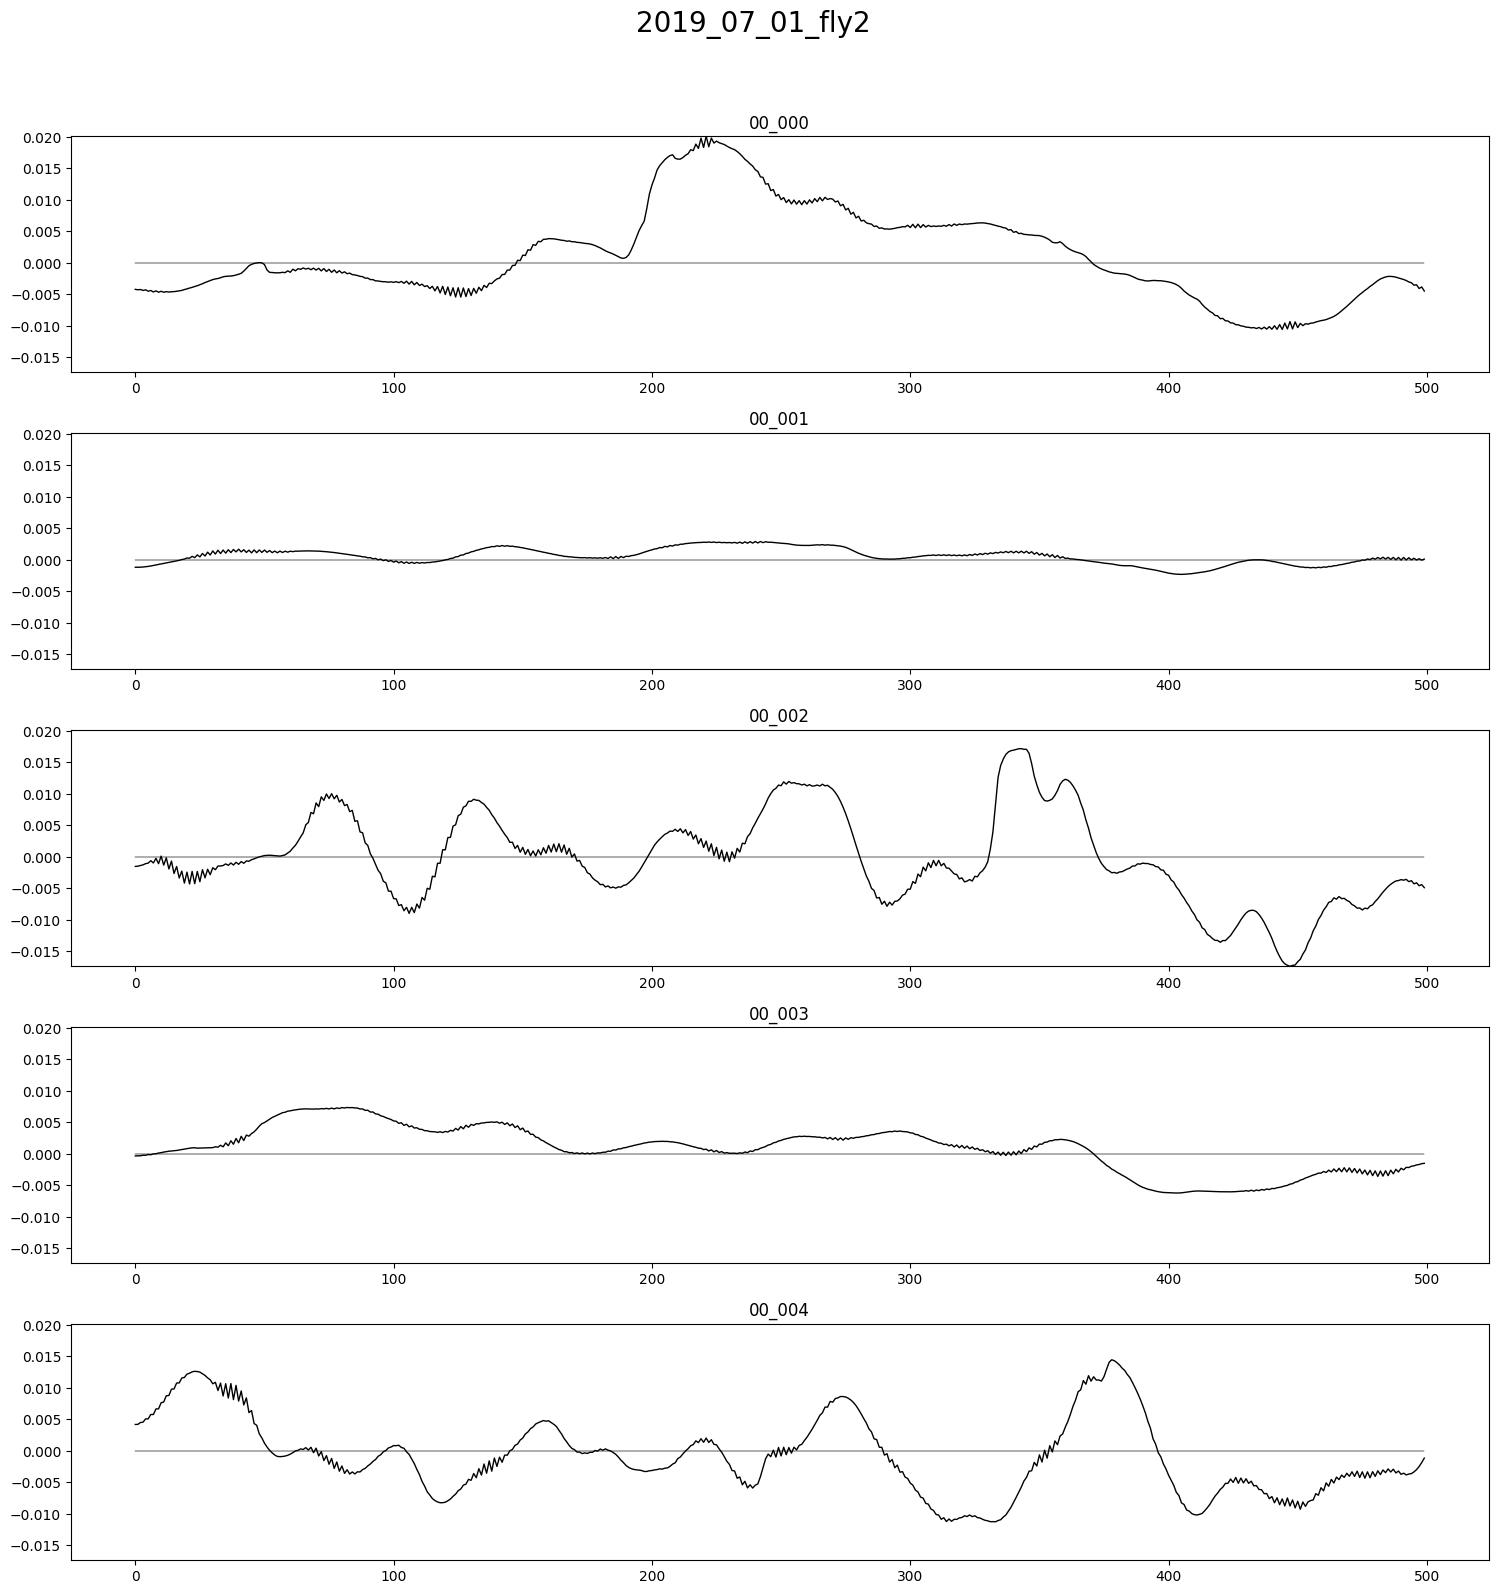

In [11]:
plot_utils.plot_traces(traces_residuals[plot_idx].iloc[:500, :5],
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

# regression

In [12]:
def r2_score_oos(y_eval, y_pred, baseline):
	ss_res = np.sum((y_eval - y_pred) ** 2)
	ss_tot = np.sum((y_eval - baseline) ** 2)
	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

def r2_score_oos_single(y_eval, y_pred, baseline):
	ss_res = np.sum((y_eval - y_pred) ** 2, axis=0)
	ss_tot = np.sum((y_eval - baseline) ** 2, axis=0)
	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

In [13]:
traces_residuals_pred = list()
r2s = list()

for i, markers_version in enumerate([markers_zs, markers_grad_zs]):
	marker = markers_version[plot_idx]
	trace = traces_residuals[plot_idx]

	X_train, X_test, y_train, y_test = train_test_split(
		marker.values, trace.values, test_size=0.2, random_state=42
	)

	lr = LinearRegression()
	lr.fit(X_train, y_train)

	y_test_pred = lr.predict(X_test)
	traces_residuals_pred.append(pd.DataFrame(data=lr.predict(marker.values), columns=trace.columns))

	r2 = r2_score_oos(y_test, y_test_pred, y_train.mean(axis=0))
	mse = mean_squared_error(y_test, y_test_pred)

	r2_single = r2_score_oos_single(y_test, y_test_pred, y_train.mean(axis=0)).reshape(-1, 1).T
	r2s.append(pd.DataFrame(data=r2_single, columns=trace.columns))

	print(i, "R²:", r2)
	print(i, "MSE:", mse)

0 R²: 0.03886203336086658
0 MSE: 1.7025706158138973e-05
1 R²: -0.0035801500340861825
1 MSE: 1.7777531773476066e-05


In [14]:
r2_indices = [np.argsort(r2s[0].values).reshape(1559,), np.argsort(r2s[1].values).reshape(1559,)]

In [15]:
print(r2s[0].iloc[:, r2_indices[0][-5:]])
print(r2s[1].iloc[:, r2_indices[1][-5:]])

    00_656    00_471    00_907    00_521    00_568
0  0.11884  0.120807  0.136607  0.140172  0.149138
    00_1303    00_912   00_1376    00_120    00_916
0  0.000125  0.000455  0.000598  0.000656  0.000961


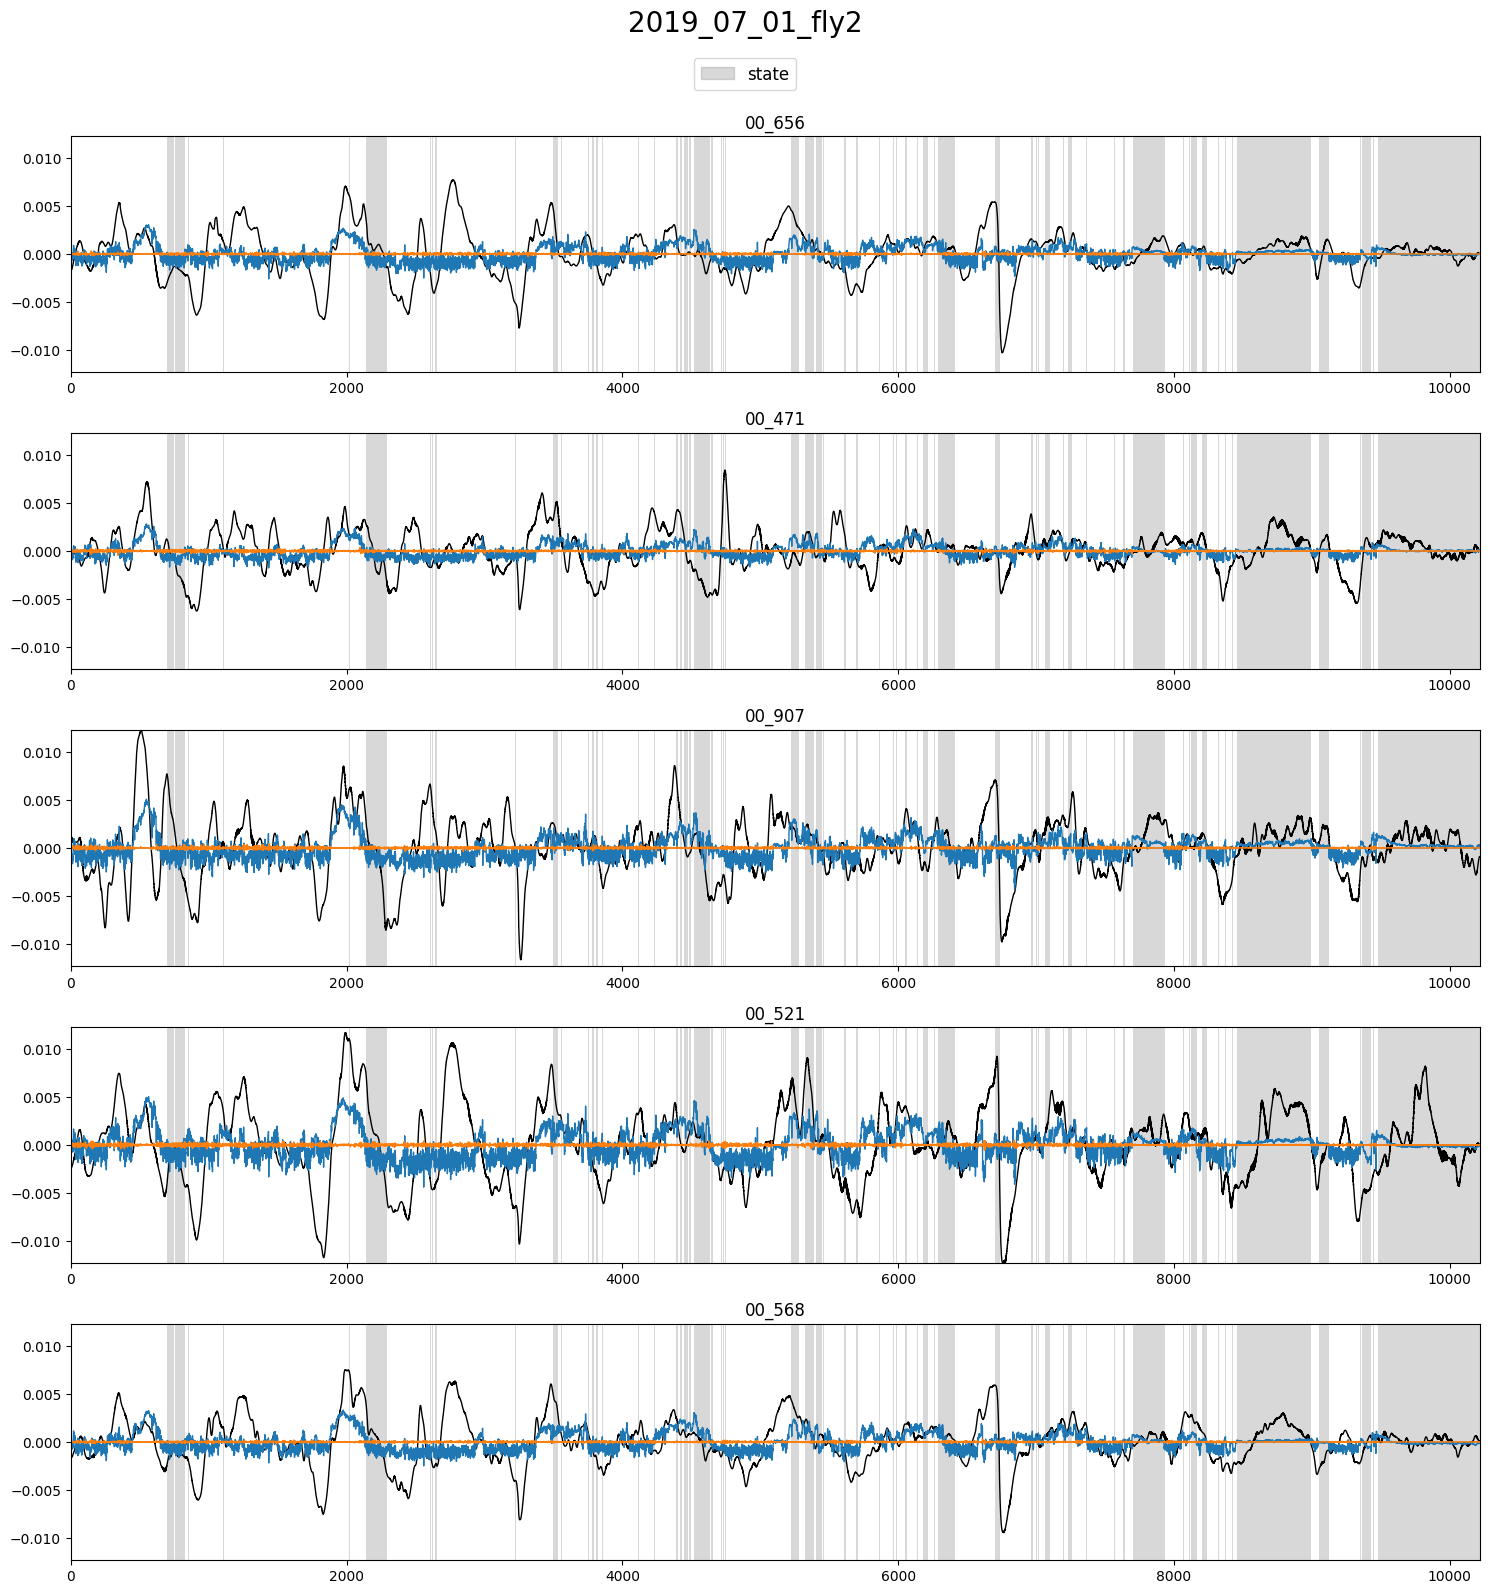

In [18]:
# max = 1000
max = traces_residuals[plot_idx].values.shape[0]
plot_utils.plot_traces([traces_residuals[plot_idx].iloc[:max, r2_indices[0][-5:]],
					    traces_residuals_pred[0].iloc[:max, r2_indices[0][-5:]],
					    traces_residuals_pred[1].iloc[:max, r2_indices[0][-5:]]],
					   states[plot_idx].loc[:max, ['still']],
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

# CCA

In [18]:
modes_concrete, modes_concrete_b = list(), list()
recos_concrete, recos_concrete_b = list(), list()
loads_cca_con, loads_cca_con_b = list(), list()
vars_expl_con, vars_expl_con_rs = list(), list()  # rs in this case: variance explained with respect to the manifold-residual data

for i, markers_version in enumerate([markers_zs, markers_grad_zs]):
	marker = markers_version[plot_idx]
	trace = traces[plot_idx]
	trace_residual = traces_residuals[plot_idx]

	n_ccv = markers_version[plot_idx].values.shape[1]

	cca = CCA(n_components=n_ccv, scale=True)

	trace_residual_reduced, marker_reduced = cca.fit_transform(trace_residual.values, marker.values)
	trace_residual_reconstructed, marker_reconstructed = cca.inverse_transform(trace_residual_reduced, marker_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CV{i + 1}' for i in range(n_ccv)]))
	recos_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	modes_concrete_b.append(pd.DataFrame(data=marker_reduced, columns=[f'CV{i + 1}' for i in range(n_ccv)]))
	recos_concrete_b.append(pd.DataFrame(data=marker_reconstructed, columns=marker.columns))

	loads_cca_con.append(cca.x_loadings_)
	loads_cca_con_b.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace.values)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual.values)
	vars_expl_con.append([var_ratio])
	vars_expl_con_rs.append([var_ratio_rs])

In [20]:
for i in range(2):
	corrs = [
		np.corrcoef(modes_concrete[i].values[:, j], modes_concrete_b[i].values[:, j])[0, 1] for j in range(modes_concrete[i].values.shape[1])
	]
	for j, corr in enumerate(corrs):
		print(f'{i}\tCV{j}: {corr:.2f}')

0	CV0: 0.94
0	CV1: 0.93
0	CV2: 0.88
0	CV3: 0.88
0	CV4: 0.85
0	CV5: 0.83
0	CV6: 0.81
0	CV7: 0.80
0	CV8: 0.79
0	CV9: 0.77
0	CV10: 0.75
0	CV11: 0.72
0	CV12: 0.69
0	CV13: 0.64
0	CV14: 0.62
0	CV15: 0.54
1	CV0: 0.50
1	CV1: 0.44
1	CV2: 0.39
1	CV3: 0.38
1	CV4: 0.34
1	CV5: 0.31
1	CV6: 0.29
1	CV7: 0.28
1	CV8: 0.28
1	CV9: 0.27
1	CV10: 0.26
1	CV11: 0.25
1	CV12: 0.25
1	CV13: 0.23
1	CV14: 0.20
1	CV15: 0.17


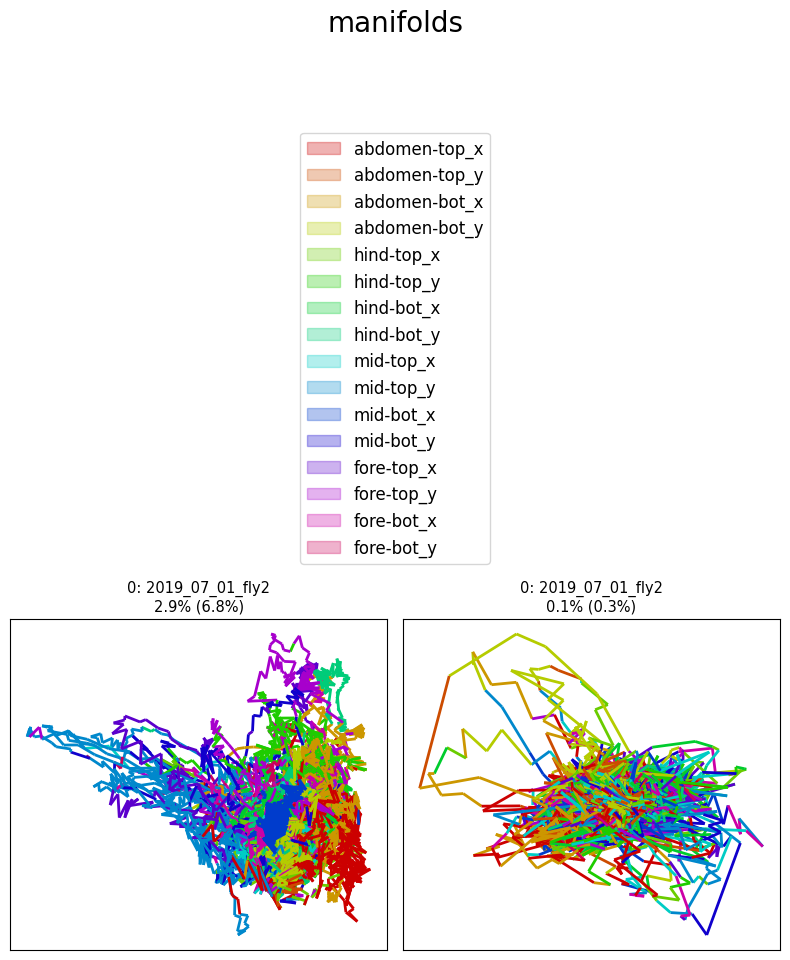

1.5% (3.6%)


In [23]:
plot_utils.plot_manifolds([f'{str(plot_id)}: {filenames[plot_idx]}'] * 2,
						  [modes_concrete[i] for i in range(2)], [markers[plot_idx] for markers in [markers_zs, markers_grad_zs]],
						  [vars_expl_con[i][:] for i in range(2)], [vars_expl_con_rs[i][:] for i in range(2)],
						  top_space=6.5)

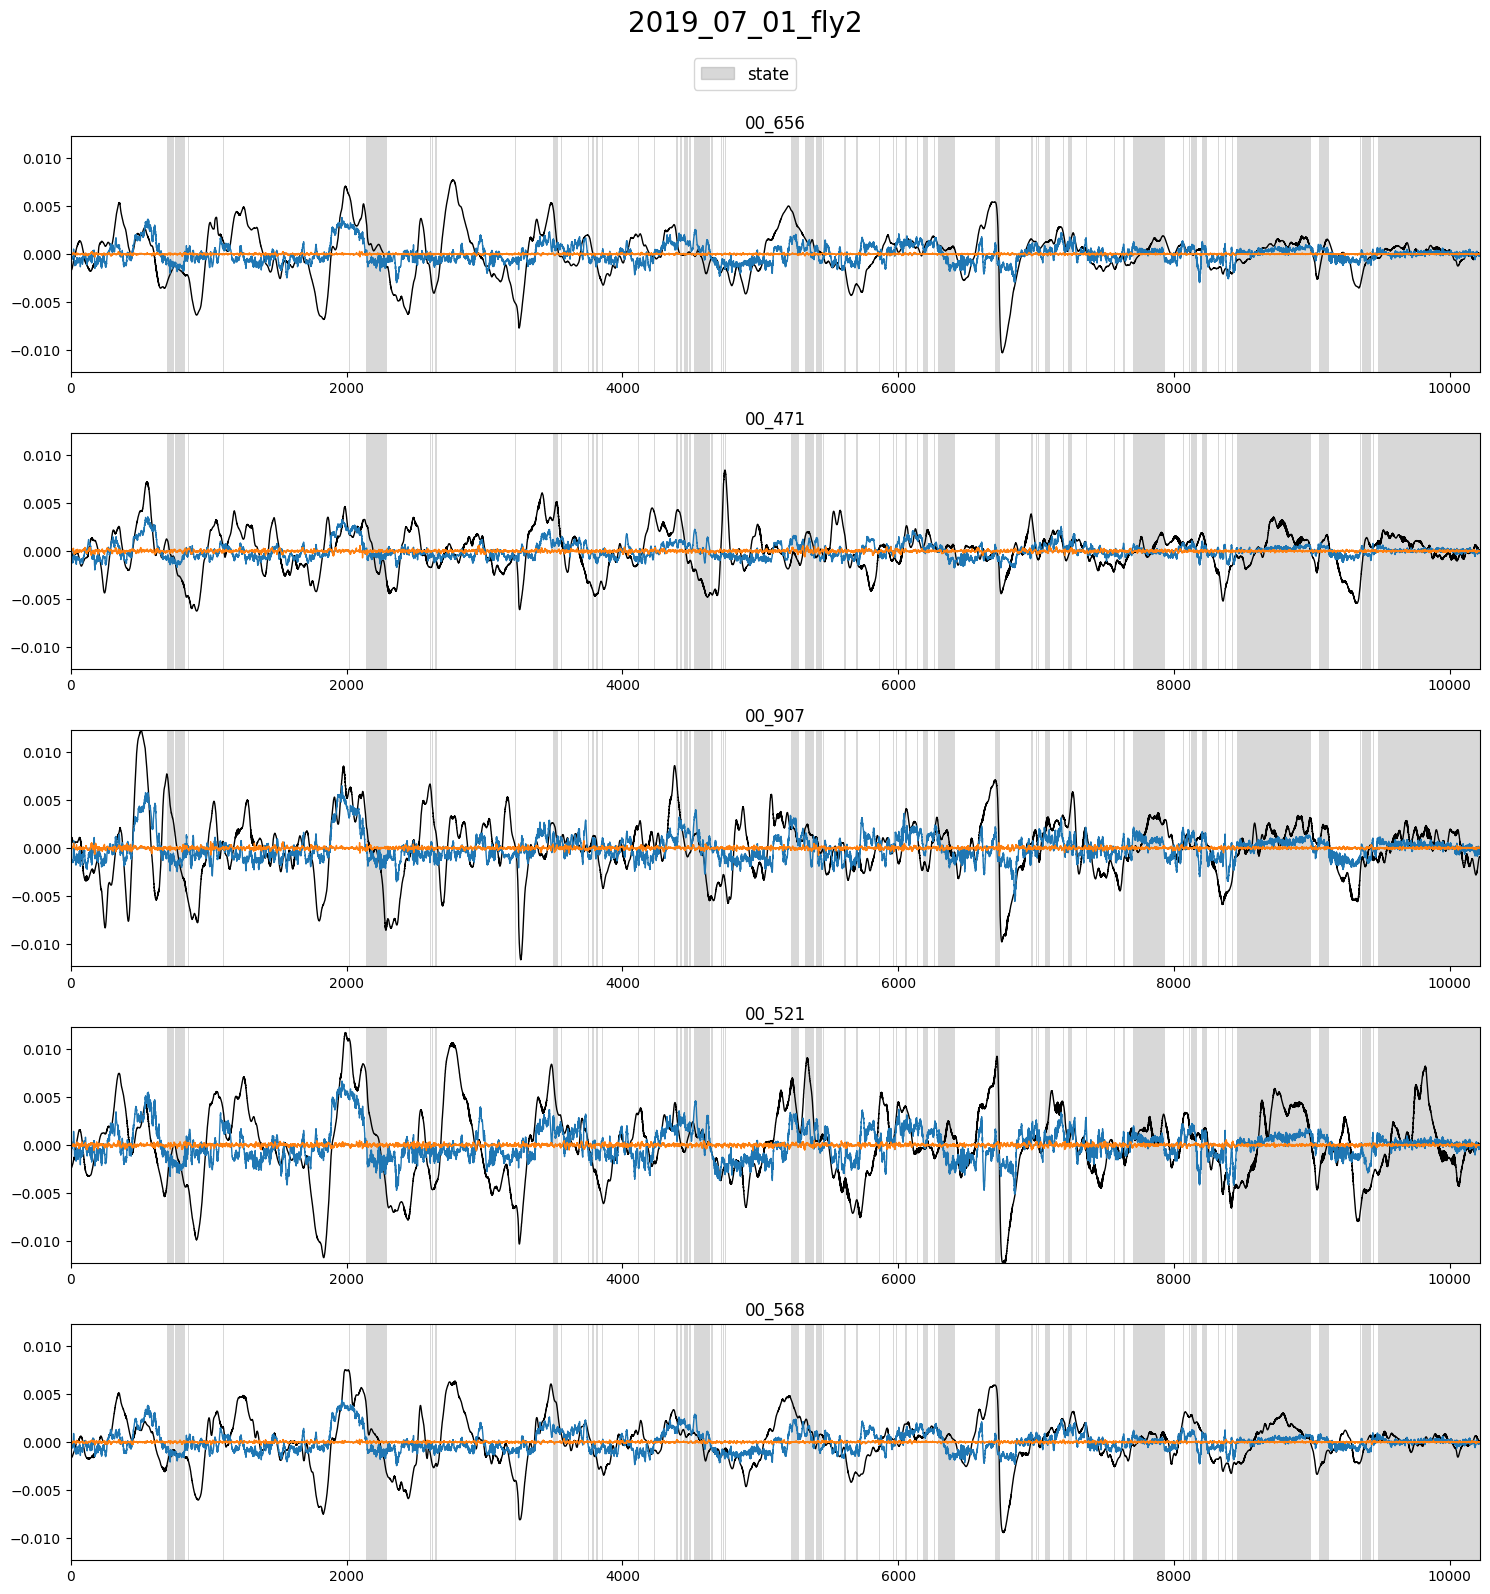

In [25]:
max = traces_residuals[plot_idx].values.shape[0]
plot_utils.plot_traces([traces_residuals[plot_idx].iloc[:max, r2_indices[0][-5:]],
					    recos_concrete[0].iloc[:max, r2_indices[0][-5:]],
					    recos_concrete[1].iloc[:max, r2_indices[0][-5:]]],
					   states[plot_idx].loc[:max, ['still']],
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

# residual subspace